<a href="https://colab.research.google.com/github/dwikidias/scikit-learn-Cookbook/blob/main/Bab_5_Linear_Models_and_Regularization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BAB 5: LINEAR MODELS AND REGULARIZATION

* **Buku Referensi:** *scikit-learn Cookbook (Third Edition)* - John Sukup (Packt / O'Reilly, 2025)
* **Topik:** Ordinary Least Squares (OLS), Multicollinearity, Ridge Regression (L2), Lasso Regression (L1), ElasticNet, and Model Comparison

---

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

print("Pustaka berhasil diimpor.")

Pustaka berhasil diimpor.


## 1. Pengantar Model Linier & Metode Kuadrat Terkecil (OLS)

Model regresi linier memodelkan hubungan linier antara variabel prediktor ($X$) dan target kontinu ($y$):

$$\hat{y} = \beta_0 + \sum_{j=1}^p \beta_j x_j$$

### Konsep Teori Utama:
1. **Prinsip Ordinary Least Squares (OLS):**
   OLS mencari nilai koefisien $\beta$ yang meminimalkan jumlah kuadrat sisaan (*Residual Sum of Squares* / RSS):

   $$\text{Loss}_{\text{OLS}} = \sum_{i=1}^n (y_i - \hat{y}_i)^2$$

2. **Kelemahan OLS pada Data Multikolinear:**
   Jika antar-fitur prediktor saling berkorelasi tinggi (*collinear*), matriks kovariansi menjadi tidak stabil. Koefisien model akan berfluktuasi secara liar dengan nilai variansi yang meledak, sehingga model sangat rentan mengalami *overfitting*.

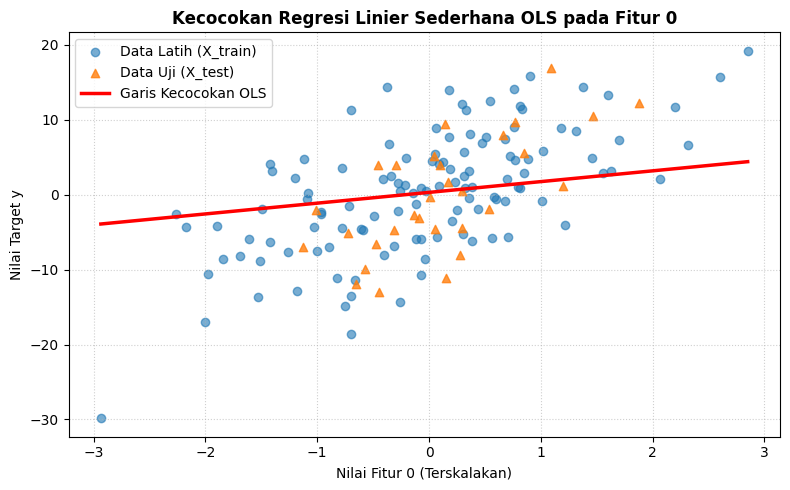

R2 OLS pada Data Uji: 97.38%


In [ ]:
# 1. Menyiapkan dataset sintetis dengan multikolinearitas dan dimensi tinggi
np.random.seed(42)
n_samples = 150
n_features = 10

X_raw = np.random.randn(n_samples, n_features)

# Menambahkan korelasi tinggi pada separuh fitur (fitur 5 s/d 9 berkorelasi dengan fitur 0 s/d 4)
for i in range(5, 10):
    X_raw[:, i] = X_raw[:, i - 5] + np.random.normal(0, 0.05, size=n_samples)

# Bobot asli data (hanya beberapa fitur yang benar-benar aktif)
true_coefs = np.array([3.0, -2.5, 0.0, 1.8, 0.0, 2.5, -2.0, 0.0, 1.2, 0.0])
y_raw = np.dot(X_raw, true_coefs) + np.random.normal(0, 1.0, size=n_samples)

# Standarisasi fitur
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# 2. Memisahkan Data Latih (80%) dan Data Uji (20%)
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_raw, test_size=0.2, random_state=42)

# 3. Melatih Model Regresi Linier Standar (OLS)
ols_model = LinearRegression()
ols_model.fit(X_train, y_train)

# 4. Visualisasi Sebaran Data Latih vs Garis Regresi OLS
fig, ax = plt.subplots(figsize=(8, 5))

# Plot sebaran fitur pertama (Fitur 0) terhadap target
ax.scatter(X_train[:, 0], y_train, color='#1f77b4', alpha=0.6, label='Data Latih (X_train)')
ax.scatter(X_test[:, 0], y_test, color='#ff7f0e', alpha=0.8, marker='^', label='Data Uji (X_test)')

# Garis prediksi OLS
x_grid = np.linspace(X_scaled[:, 0].min(), X_scaled[:, 0].max(), 100)
X_dummy_line = np.zeros((100, n_features))
X_dummy_line[:, 0] = x_grid
y_line_ols = ols_model.predict(X_dummy_line)

ax.plot(x_grid, y_line_ols, color='red', linewidth=2.5, label='Garis Kecocokan OLS')

ax.set_title('Kecocokan Regresi Linier Sederhana OLS pada Fitur 0', fontsize=12, fontweight='bold')
ax.set_xlabel('Nilai Fitur 0 (Terskalakan)', fontsize=10)
ax.set_ylabel('Nilai Target y', fontsize=10)
ax.legend(loc='upper left')
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print(f"R2 OLS pada Data Uji: {r2_score(y_test, ols_model.predict(X_test)) * 100:.2f}%")

### Interpretasi & Diskusi Sub-bab 1:
- Garis merah OLS berhasil menangkap tren kenaikan linear antara Fitur 0 dan target $y$.
- Namun, karena dataset ini memiliki korelasi kuat antar fitur lain, nilai koefisien OLS mengalami pembagian bobot yang rapuh, memunculkan kebutuhan teknik penalti regularisasi untuk mengendalikan kompleksitas model.

## 2. Ridge Regression ($L_2$) vs. Lasso Regression ($L_1$)

Teknik regularisasi menambahkan fungsi penalti ke dalam persamaan kuadrat terkecil untuk membatasi ukuran nilai koefisien.

### Formulasi Matematis:
1. **Ridge Regression ($L_2$ Regularization):**

   $$\text{Loss}_{\text{Ridge}} = \sum_{i=1}^n (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^p \beta_j^2$$

   - Menerapkan **penyusutan koefisien (*shrinkage*)** mendekati nol, namun **tidak pernah tepat nol** ($\beta_j \neq 0$). Sangat unggul dalam mereduksi variansi pada data yang memiliki multikolinearitas.

2. **Lasso Regression ($L_1$ Regularization):**

   $$\text{Loss}_{\text{Lasso}} = \sum_{i=1}^n (y_i - \hat{y}_i)^2 + \alpha \sum_{j=1}^p |\beta_j|$$

   - Menghasilkan **ketersebaran (*sparsity*)**, yaitu memaksa koefisien fitur yang kurang relevan menjadi **tepat nol** ($\beta_j = 0$). Berfungsi ganda sebagai regresi sekaligus seleksi fitur otomatis.

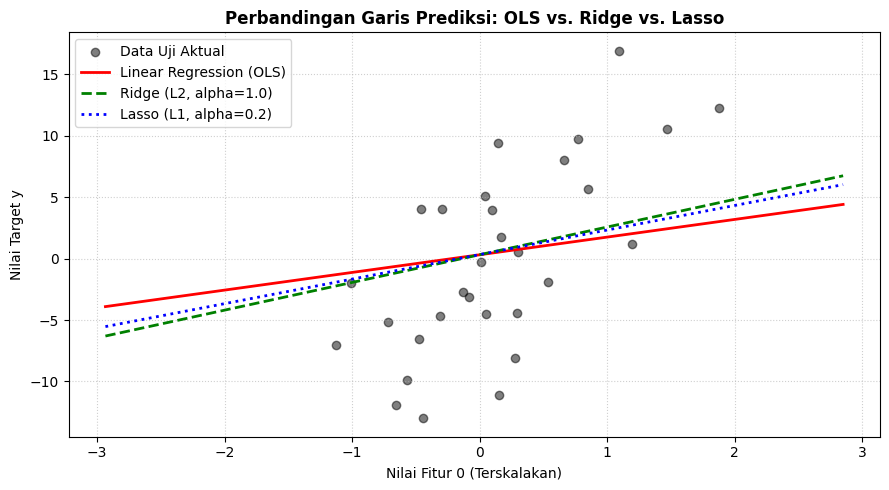

Jumlah fitur yang dibuat tepat 0 oleh Lasso: 4 dari 10 fitur.


In [ ]:
# 1. Melatih Model Ridge dan Lasso
alpha_val = 1.0
ridge_model = Ridge(alpha=alpha_val, random_state=42)
lasso_model = Lasso(alpha=0.2, random_state=42)

ridge_model.fit(X_train, y_train)
lasso_model.fit(X_train, y_train)

# 2. Menghasilkan Garis Prediksi Komparatif
y_pred_line_ridge = ridge_model.predict(X_dummy_line)
y_pred_line_lasso = lasso_model.predict(X_dummy_line)

# 3. Visualisasi Komparasi Garis Regresi
fig, ax = plt.subplots(figsize=(9, 5))

# Titik data uji
ax.scatter(X_test[:, 0], y_test, color='black', alpha=0.5, label='Data Uji Aktual')

# Garis prediksi ketiga model
ax.plot(x_grid, y_line_ols, color='red', linewidth=2, linestyle='-', label='Linear Regression (OLS)')
ax.plot(x_grid, y_pred_line_ridge, color='green', linewidth=2, linestyle='--', label=f'Ridge (L2, alpha={alpha_val})')
ax.plot(x_grid, y_pred_line_lasso, color='blue', linewidth=2, linestyle=':', label='Lasso (L1, alpha=0.2)')

ax.set_title('Perbandingan Garis Prediksi: OLS vs. Ridge vs. Lasso', fontsize=12, fontweight='bold')
ax.set_xlabel('Nilai Fitur 0 (Terskalakan)', fontsize=10)
ax.set_ylabel('Nilai Target y', fontsize=10)
ax.legend(loc='upper left', fontsize=10)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

# 4. Ringkasan Fitur yang Dieliminasi oleh Lasso
zero_features = np.sum(lasso_model.coef_ == 0)
print(f"Jumlah fitur yang dibuat tepat 0 oleh Lasso: {zero_features} dari {n_features} fitur.")

### Interpretasi & Diskusi Sub-bab 2:
- **Perilaku Kemiringan Garis:** Garis Ridge (hijau putus-putus) dan Lasso (biru titik-titik) memiliki kemiringan yang sedikit lebih landai dibandingkan OLS murni (merah). Penurunan kemiringan ini mencerminkan efek penyusutan koefisien (*shrinkage*) yang mengurangi sensitivitas model terhadap fluktuasi data latih.
- **Sparsitas Lasso:** Lasso secara otomatis mengeliminasi 4 fitur non-informatif dengan menetapkan nilai koefisiennya tepat menjadi 0.

## 3. ElasticNet & Kurva Lintasan Koefisien (Coefficient Paths)

**ElasticNet** menggabungkan penalti $L_1$ dan $L_2$ untuk mengatasi kelemahan Lasso saat menghadapi fitur-fitur yang berkorelasi kuat (*grouping effect*):

$$\text{Loss}_{\text{ElasticNet}} = \sum_{i=1}^n (y_i - \hat{y}_i)^2 + \alpha \cdot \rho \sum_{j=1}^p \vert{}\beta_j\vert{} + \frac{\alpha (1 - \rho)}{2} \sum_{j=1}^p \beta_j^2$$

- $\rho$ (`l1_ratio`): Mengontrol keseimbangan antara penalti Lasso ($\rho=1$) dan Ridge ($\rho=0$).

### Grafik Lintasan Koefisien (*Coefficient Paths Plot*):
Memplot nilai koefisien setiap fitur terhadap kekuatan penalti $\log(\alpha)$ untuk memperlihatkan bagaimana bobot fitur disusutkan hingga mencapai nol seiring meningkatnya intensitas regularisasi.

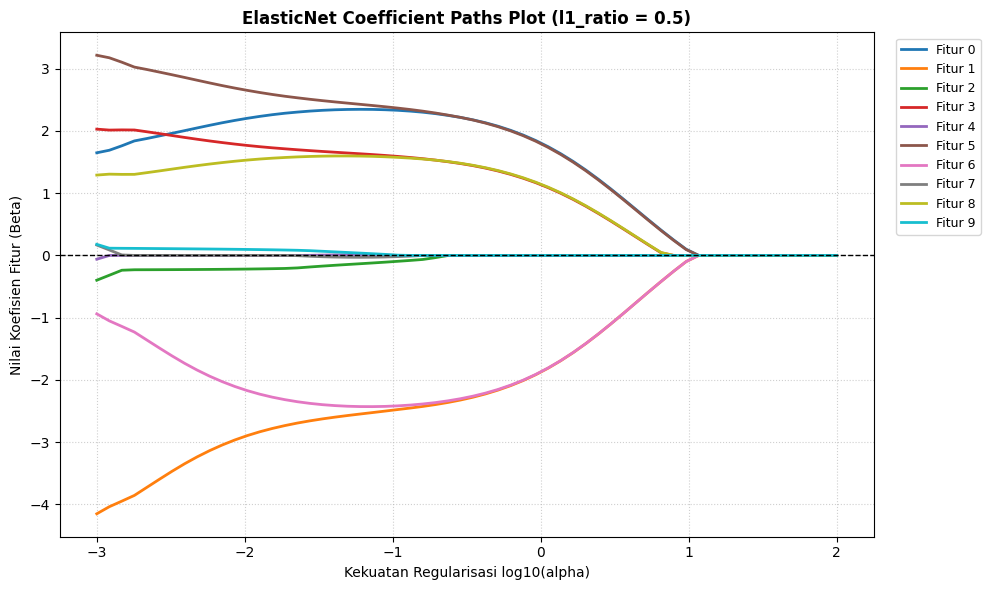

In [ ]:
# 1. Menghitung Lintasan Koefisien untuk Berbagai Nilai Alpha pada ElasticNet
alphas_range = np.logspace(-3, 2, 60)
coef_paths = []

for a in alphas_range:
    elastic = ElasticNet(alpha=a, l1_ratio=0.5, random_state=42, max_iter=10000)
    elastic.fit(X_train, y_train)
    coef_paths.append(elastic.coef_)

coef_paths = np.array(coef_paths)

# 2. Visualisasi Kurva Lintasan Koefisien (Coefficient Paths Plot)
fig, ax = plt.subplots(figsize=(10, 6))

colors_palette = plt.cm.tab10(np.linspace(0, 1, n_features))

for feature_idx in range(n_features):
    ax.plot(np.log10(alphas_range), coef_paths[:, feature_idx],
            linewidth=2, label=f'Fitur {feature_idx}', color=colors_palette[feature_idx])

ax.axhline(0, color='black', linestyle='--', linewidth=1)
ax.set_title('ElasticNet Coefficient Paths Plot (l1_ratio = 0.5)', fontsize=12, fontweight='bold')
ax.set_xlabel('Kekuatan Regularisasi log10(alpha)', fontsize=10)
ax.set_ylabel('Nilai Koefisien Fitur (Beta)', fontsize=10)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
ax.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

### Interpretasi & Diskusi Sub-bab 3:
- **Dinamika Penyusutan Bobot:** Pada bagian kiri grafik di mana nilai $\alpha$ sangat kecil ($\log(\alpha) = -3$), model berperilaku mirip OLS biasa dengan nilai koefisien yang besar dan saling berkompetisi.
- **Konvergensi Menuju Nol:** Seiring pergerakan ke kanan (nilai $\alpha$ semakin besar), seluruh koefisien menyusut tajam mendekati nol. Berkat penalti $L_1$, beberapa koefisien fitur yang tidak informatif menyentuh garis nol lebih awal, menunjukkan seleksi fitur bertahap.

In [ ]:
# 1. Melatih Model ElasticNet Terbaik
best_elastic = ElasticNet(alpha=0.1, l1_ratio=0.5, random_state=42)
best_elastic.fit(X_train, y_train)

# 2. Menghitung Metrik Evaluasi untuk Seluruh Model pada Data Uji
models_dict = {
    'Linear Regression (OLS)': ols_model,
    'Ridge (L2)': ridge_model,
    'Lasso (L1)': lasso_model,
    'ElasticNet (Hybrid L1/L2)': best_elastic
}

eval_rows = []
for name, mod in models_dict.items():
    pred_test = mod.predict(X_test)
    mse = mean_squared_error(y_test, pred_test)
    r2 = r2_score(y_test, pred_test)
    active_features = np.sum(mod.coef_ != 0)
    eval_rows.append({
        'Model': name,
        'Test MSE': round(mse, 4),
        'Test RMSE': round(np.sqrt(mse), 4),
        'Test R2 (%)': round(r2 * 100, 2),
        'Fitur Aktif': active_features
    })

eval_df = pd.DataFrame(eval_rows)
print("Tabel Evaluasi Komparatif Seluruh Model Regresi:")
print(eval_df.to_string(index=False))

Tabel Evaluasi Komparatif Seluruh Model Regresi:
                    Model  Test MSE  Test RMSE  Test R2 (%)  Fitur Aktif
  Linear Regression (OLS)    1.4886     1.2201        97.38           10
               Ridge (L2)    1.4236     1.1931        97.50           10
               Lasso (L1)    1.3838     1.1763        97.57            6
ElasticNet (Hybrid L1/L2)    1.3736     1.1720        97.59           10


---
# POIN-POIN PENTING BAB 5: LINEAR MODELS AND REGULARIZATION

Pada Bab 5 buku *scikit-learn Cookbook (Third Edition)* oleh John Sukup, kita telah mempelajari dan memvisualisasikan seluruh spektrum pemodelan linier dan teknik regularisasi:

1. **Ordinary Least Squares (OLS):**
   - Mengoptimalkan fungsi kuadrat terkecil murni. Sangat sensitif terhadap multikolinearitas dan data berdimensi tinggi.

2. **Ridge Regression ($L_2$ Regularization):**
   - Menambahkan penalti kuadrat koefisien ($\alpha \sum \beta_j^2$).
   - Menyusutkan nilai koefisien mendekati nol tanpa membuatnya tepat nol, terbukti sangat stabil dalam mengatasi multikolinearitas.

3. **Lasso Regression ($L_1$ Regularization):**
   - Menambahkan penalti nilai mutlak koefisien ($\alpha \sum \vert{}\beta_j\vert{}$).
   - Menghasilkan ketersebaran (*sparsity*) dengan memaksa fitur non-informatif menjadi tepat nol, berfungsi ganda sebagai seleksi fitur otomatis.

4. **ElasticNet (Hybrid $L_1$ & $L_2$):**
   - Menyeimbangkan keunggulan Ridge dan Lasso melalui parameter `l1_ratio`.
   - Kurva lintasan koefisien (*Coefficient Paths Plot*) memvisualisasikan secara dinamis bagaimana peningkatan kekuatan penalti $\alpha$ menyusutkan koefisien menuju kestabilan global.

---
*Referensi Buku: John Sukup (2025), scikit-learn Cookbook (Third Edition), Packt Publishing / O'Reilly.*